<a href="https://colab.research.google.com/github/asegura4488/MetodosComputacionales2026/blob/main/Semana14/ModeloRiesgo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import os
os.chdir('/content/drive/MyDrive/ColabNotebooks/Cursos/MetodosComputacionales2026')

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [5]:
df = pd.read_csv('Semana14/Data/datos_materias_riesgo.csv')

In [6]:
df

,Materia,Parcial_1,Parcial_2,Hora_clase,Horas_estudio_semana,Dificultad_profesor_1a5
0,Calculo,2.4,2.8,07:00,5,4
1,Algebra Lineal,3.0,2.9,10:00,4,3
2,Fisica Moderna,2.1,2.5,16:00,7,5


In [7]:
# Umbral
nota_aprobacion = 3.0
peso_p1 = 0.30
peso_p2 = 0.30
peso_faltante = 0.4

In [9]:
df['Nota_acumulada'] = peso_p1 * df['Parcial_1'] + peso_p2 * df['Parcial_2']

In [10]:
df

,Materia,Parcial_1,Parcial_2,Hora_clase,Horas_estudio_semana,Dificultad_profesor_1a5,Nota_acumulada
0,Calculo,2.4,2.8,07:00,5,4,1.56
1,Algebra Lineal,3.0,2.9,10:00,4,3,1.77
2,Fisica Moderna,2.1,2.5,16:00,7,5,1.38


In [11]:
df['Nota_necesaria'] = (nota_aprobacion - df['Nota_acumulada']) / (1 - peso_p1 - peso_p2)
df['Nota_necesaria']

,Nota_necesaria
0,3.600
1,3.075
2,4.050


In [14]:
df['R_nota'] = df['Nota_necesaria'] / 5
df['R_profesor'] = df['Dificultad_profesor_1a5'] / 5
df['R_tiempo'] = df['Horas_estudio_semana']/ df['Horas_estudio_semana'].max()

In [15]:
df

,Materia,Parcial_1,Parcial_2,Hora_clase,Horas_estudio_semana,Dificultad_profesor_1a5,Nota_acumulada,Nota_necesaria,R_nota,R_profesor,R_tiempo
0,Calculo,2.4,2.8,07:00,5,4,1.56,3.600,0.720,0.8,0.714286
1,Algebra Lineal,3.0,2.9,10:00,4,3,1.77,3.075,0.615,0.6,0.571429
2,Fisica Moderna,2.1,2.5,16:00,7,5,1.38,4.050,0.810,1.0,1.000000


In [16]:
w1 = []
w1.append(0.4)
w1.append(0.4)
w1.append(0.5)
w1.append(0.5)
w1.append(0.4)
w1.append(0.5)
w1.append(0.4)
w1.append(0.4)
w1.append(0.5)
w1.append(0.6)
w1.append(0.4)
w1.append(0.5)
w1.append(0.6)
w1.append(0.7)
w1.append(0.6)
w1.append(0.6)
w1.append(0.6)
w1.append(0.6)
w1.append(0.5)
w1.append(0.3)
w1.append(0.4)
w1.append(0.6)
w1.append(0.5)
w1.append(0.5)
w1.append(0.6)
w1.append(0.7)
w1.append(0.5)
w1.append(0.5)
w1.append(0.6)
w1.append(0.5)

(array([ 1.,  0.,  7.,  0.,  0., 11.,  0.,  9.,  0.,  2.]),
 array([0.3 , 0.34, 0.38, 0.42, 0.46, 0.5 , 0.54, 0.58, 0.62, 0.66, 0.7 ]),
 <BarContainer object of 10 artists>)

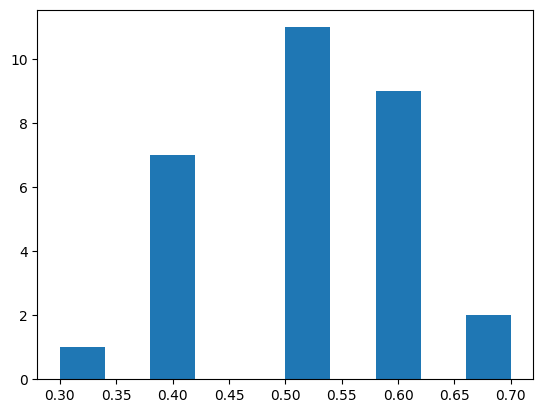

In [19]:
plt.hist(w1,bins=10)

In [20]:
np.mean(w1)

np.float64(0.5133333333333333)

In [22]:
np.std(w1)

np.float64(0.09568466729604881)